# Reliability Index and FORM: From Probability of Failure to a Geometric Search

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L14/L14_reliability_index_and_form.ipynb)
### MECH 559 - Systems Optimization - L14
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the "Reliability-based design optimization (RBDO)" slides.
A limit-state function $G(\mathbf X)$ splits input space into safe ($G>0$) and
failure ($G\le0$); the probability of failure $P_f=\Pr(G(\mathbf X)\le0)$ is
generally an intractable integral. This notebook estimates $P_f$ by brute-force
Monte Carlo, then builds FORM's reliability index $\beta$ as an honest constrained
optimization -- $\beta=\min_{\mathbf u}\|\mathbf u\|$ s.t. $G(\mathbf u)=0$ in
standard normal space -- and uses it to size a design for a target reliability,
exactly the inner-loop/outer-loop structure of double-loop RBDO.

## Learning objectives

1. Estimate a probability of failure by Monte Carlo, and check it against a
   closed-form result for a linear limit state.
2. Compute the reliability index $\beta$ as $\min\|\mathbf u\|$ s.t.
   $G(\mathbf u)=0$ with `scipy.optimize.minimize`, locate the most probable
   point (MPP), and visualize it exactly as on the slide.
3. Apply FORM to a nonlinear limit state and see the (small but nonzero) gap
   between $\Phi(-\beta)$ and the Monte Carlo $P_f$ that linearization causes.
4. Run the RBDO "outer loop, inner loop" idea directly: sweep a design mean and
   use FORM inside a root-find to size it for a target $\beta$.

> **Classroom rhythm:** pause at each **Predict** prompt before running the next
> cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, brentq

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
COLORS = {"safe": "#2A9D5C", "fail": "#D1495B", "mpp": "#D1495B", "line": "#264653"}
rng = np.random.default_rng(559)
print(f"NumPy {np.__version__}")

NumPy 2.5.2


---
## 1. A linear limit state: strength vs. stress

$G(\mathbf X)=R-S$, with resistance $R\sim\mathcal N(\mu_R,\sigma_R^2)$ (e.g. a
material's yield strength) and load effect $S\sim\mathcal N(\mu_S,\sigma_S^2)$,
independent. Because $G$ is a linear combination of two normals, $G$ itself is
normal, giving a closed-form ground truth:

$$
G\sim\mathcal N(\mu_R-\mu_S,\ \sigma_R^2+\sigma_S^2), \qquad
\beta=\frac{\mu_R-\mu_S}{\sqrt{\sigma_R^2+\sigma_S^2}}, \qquad
P_f=\Phi(-\beta).
$$

> **Predict:** with $\mu_R=50$, $\sigma_R=5$, $\mu_S=30$, $\sigma_S=6$ (arbitrary
> consistent stress units), will $P_f$ be closer to $10^{-1}$, $10^{-3}$, or
> $10^{-6}$?

In [2]:
mu_R, sigma_R = 50.0, 5.0
mu_S, sigma_S = 30.0, 6.0

def G_linear(R, S):
    return R - S

beta_closed_form = (mu_R - mu_S) / np.sqrt(sigma_R ** 2 + sigma_S ** 2)
Pf_closed_form = stats.norm.cdf(-beta_closed_form)

N = 3_000_000
Rs = rng.normal(mu_R, sigma_R, N)
Ss = rng.normal(mu_S, sigma_S, N)
Pf_mc = np.mean(G_linear(Rs, Ss) <= 0)

print(f"closed-form beta        = {beta_closed_form:.4f}")
print(f"closed-form Pf = Phi(-beta) = {Pf_closed_form:.6f}")
print(f"Monte Carlo Pf (N={N:,})  = {Pf_mc:.6f}")

closed-form beta        = 2.5607
closed-form Pf = Phi(-beta) = 0.005223
Monte Carlo Pf (N=3,000,000)  = 0.005192


The Monte Carlo estimate matches the closed form to within sampling noise --
our reliability machinery is doing the right thing before we even introduce FORM.

---
## 2. FORM as a constrained optimization

Transform to independent standard normal variables: $R=\mu_R+\sigma_R u_1$,
$S=\mu_S+\sigma_S u_2$. The reliability index is the shortest distance from the
origin to the limit-state surface (slide "Reliability index and FORM"):

$$
\beta = \min_{\mathbf u}\|\mathbf u\| \quad\text{s.t.}\quad G(\mathbf u)=0.
$$

For a linear $G$, this has to reproduce the closed-form $\beta$ above exactly --
a solid check before trusting the same machinery on a nonlinear $G$ in Section 3.

In [3]:
def G_u_linear(u):
    R = mu_R + sigma_R * u[0]
    S = mu_S + sigma_S * u[1]
    return R - S

res = minimize(lambda u: u[0] ** 2 + u[1] ** 2, x0=[0.0, 0.0],
                constraints={"type": "eq", "fun": G_u_linear}, method="SLSQP")
u_star = res.x
beta_form = np.linalg.norm(u_star)
Pf_form = stats.norm.cdf(-beta_form)

print(f"MPP u*      = [{u_star[0]:.4f}, {u_star[1]:.4f}]")
print(f"FORM beta   = {beta_form:.4f}   (closed form: {beta_closed_form:.4f})")
print(f"FORM Pf     = {Pf_form:.6f}")

MPP u*      = [-1.6393, 1.9672]
FORM beta   = 2.5607   (closed form: 2.5607)
FORM Pf     = 0.005223


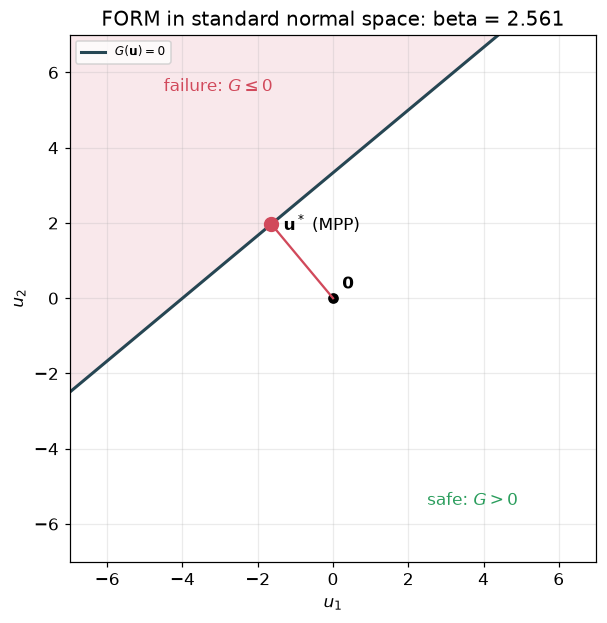

In [4]:
u1_line = np.linspace(-7, 7, 60)
u2_line = (mu_R - mu_S + sigma_R * u1_line) / sigma_S

fig, ax = plt.subplots(figsize=(5.8, 5.8))
ax.plot(u1_line, u2_line, color=COLORS["line"], lw=2, label=r"$G(\mathbf{u})=0$")
ax.fill_between(u1_line, u2_line, 8, color=COLORS["fail"], alpha=0.12)
ax.text(-4.5, 5.5, "failure: $G\\leq 0$", color=COLORS["fail"])
ax.text(2.5, -5.5, "safe: $G>0$", color=COLORS["safe"])
ax.plot(0, 0, "o", color="black", ms=6)
ax.annotate(r"$\mathbf{0}$", (0, 0), textcoords="offset points", xytext=(6, 6))
ax.plot(*u_star, "o", color=COLORS["mpp"], ms=9)
ax.annotate(r"$\mathbf{u}^*$ (MPP)", u_star, textcoords="offset points", xytext=(8, -4))
ax.plot([0, u_star[0]], [0, u_star[1]], color=COLORS["mpp"], lw=1.5)
ax.set_xlim(-7, 7); ax.set_ylim(-7, 7); ax.set_aspect("equal")
ax.set_xlabel("$u_1$"); ax.set_ylabel("$u_2$")
ax.set_title(f"FORM in standard normal space: beta = {beta_form:.3f}")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

This is exactly the slide's picture, with real numbers: the shortest vector from
the origin to $G(\mathbf u)=0$ lands on the most probable combination of $(R,S)$
that causes failure -- the *most probable point* -- and its length is $\beta$.

---
## 3. A nonlinear limit state

Now let capacity be a *product* of two random variables -- cross-sectional area
$X_1$ (in$^2$) and material strength $X_2$ (ksi) -- resisting a fixed demand
force $D_0$ (kips):

$$
G(X_1,X_2) = X_1 X_2 - D_0.
$$

$G$ is nonlinear in $(X_1,X_2)$, so FORM's linear approximation is no longer
exact -- but it should still be close if the design has reasonable margin.

> **Predict:** will $\Phi(-\beta_{\text{FORM}})$ match the Monte Carlo $P_f$
> exactly, approximately, or not at all for this nonlinear case?

In [5]:
mu_a, sigma_a = 2.0, 0.15   # area, in^2
mu_s, sigma_s = 36.0, 3.0  # strength, ksi
D0 = 65.0                  # demand, kips

def G_u_nonlinear(u, mu_a_local=mu_a):
    X1 = mu_a_local + sigma_a * u[0]
    X2 = mu_s + sigma_s * u[1]
    return X1 * X2 - D0

res_nl = minimize(lambda u: u[0] ** 2 + u[1] ** 2, x0=[0.0, 0.0],
                   constraints={"type": "eq", "fun": G_u_nonlinear}, method="SLSQP")
beta_nl = np.linalg.norm(res_nl.x)
Pf_form_nl = stats.norm.cdf(-beta_nl)

N = 3_000_000
X1s = rng.normal(mu_a, sigma_a, N)
X2s = rng.normal(mu_s, sigma_s, N)
Pf_mc_nl = np.mean(X1s * X2s - D0 <= 0)

print(f"nominal capacity mu_a*mu_s = {mu_a*mu_s:.2f} kips  (demand D0 = {D0} kips)")
print(f"FORM beta        = {beta_nl:.4f}")
print(f"FORM Pf = Phi(-beta) = {Pf_form_nl:.6f}")
print(f"Monte Carlo Pf (N={N:,}) = {Pf_mc_nl:.6f}")
print(f"relative gap FORM vs MC = {abs(Pf_form_nl-Pf_mc_nl)/Pf_mc_nl*100:.1f}%")

nominal capacity mu_a*mu_s = 72.00 kips  (demand D0 = 65.0 kips)
FORM beta        = 0.8891
FORM Pf = Phi(-beta) = 0.186982
Monte Carlo Pf (N=3,000,000) = 0.195106
relative gap FORM vs MC = 4.2%


FORM's first-order estimate is close to the Monte Carlo value but not identical
-- the residual gap is exactly the price of linearizing a curved limit-state
surface at a single point (the MPP). This is the motivation for SORM
(second-order reliability method), which adds a curvature correction at the MPP,
mentioned but not implemented here.

---
## 4. Sizing a design for a target reliability

The RBDO slide replaces $c_j(x)\le0$ with a chance constraint
$\Pr(g_j(x,\mathbf X)\le0)\ge R_j^{\text{req}}$, equivalently $\beta_j(x)\ge
\beta_j^{\text{target}}$, and solves it with a **double loop**: an outer loop over
the design $x$, and an inner FORM analysis for each candidate $x$. Here the
"outer loop" is a 1-D root-find over the mean area $\mu_a$ (the design variable),
and the "inner loop" is exactly the FORM optimization from Section 3, called once
per outer trial value.

> **Predict:** to raise $\beta$ from Section 3's value up to a common design
> target of $\beta=3.0$ (roughly $P_f\approx1.3\times10^{-3}$), will the required
> mean area be larger or smaller than the current $\mu_a=2.0$?

current design:  mu_a = 2.000 in^2  ->  beta = 0.889
RBDO design:     mu_a* = 2.5298 in^2  ->  beta = 3.000  (target 3.0)


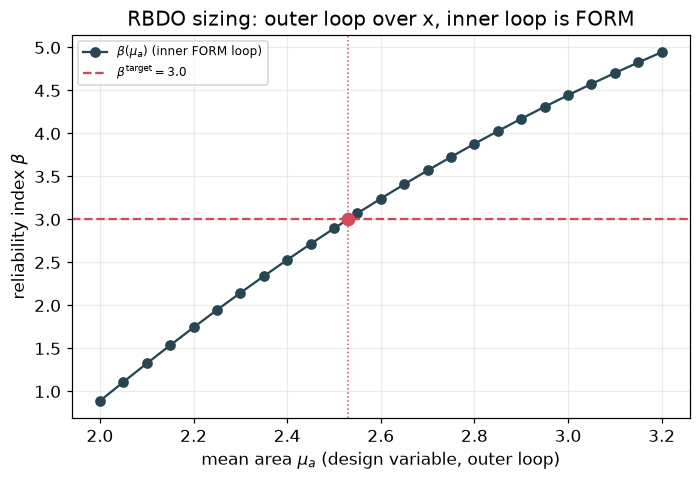

In [6]:
def beta_of_mu_a(mu_a_trial):
    res_inner = minimize(lambda u: u[0] ** 2 + u[1] ** 2, x0=[0.0, 0.0],
                          constraints={"type": "eq", "fun": lambda u: G_u_nonlinear(u, mu_a_trial)},
                          method="SLSQP")
    return np.linalg.norm(res_inner.x)

beta_target = 3.0
mu_a_grid = np.linspace(2.0, 3.2, 25)  # stay on the branch where mean capacity > demand (beta rises monotonically)
beta_grid = np.array([beta_of_mu_a(m) for m in mu_a_grid])

mu_a_star = brentq(lambda m: beta_of_mu_a(m) - beta_target, 2.0, 3.2)
print(f"current design:  mu_a = {mu_a:.3f} in^2  ->  beta = {beta_of_mu_a(mu_a):.3f}")
print(f"RBDO design:     mu_a* = {mu_a_star:.4f} in^2  ->  beta = {beta_of_mu_a(mu_a_star):.3f}  (target {beta_target})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(mu_a_grid, beta_grid, "o-", color=COLORS["line"], label=r"$\beta(\mu_a)$ (inner FORM loop)")
ax.axhline(beta_target, color=COLORS["fail"], ls="--", label=r"$\beta^{\rm target}=3.0$")
ax.axvline(mu_a_star, color=COLORS["fail"], ls=":", lw=1)
ax.plot(mu_a_star, beta_target, "o", color=COLORS["fail"], ms=8)
ax.set(xlabel=r"mean area $\mu_a$ (design variable, outer loop)", ylabel=r"reliability index $\beta$",
       title="RBDO sizing: outer loop over x, inner loop is FORM")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Each point on the curve required one full inner FORM optimization -- this is,
concretely, why double-loop RBDO can be expensive: `brentq`'s root-find called
`beta_of_mu_a` (and therefore an inner `minimize`) several times just for this
single design variable and single constraint. A real RBDO problem with several
design variables and several probabilistic constraints multiplies that cost,
which is exactly why the slide flags decoupled and single-loop strategies as
practical alternatives to the naive nested loop.

---
## Takeaways

1. For a linear limit state with normal variables, FORM's $\beta$ (solved as a
   constrained optimization) reproduces the closed-form value exactly, and
   $\Phi(-\beta)$ matches Monte Carlo's $P_f$.
2. The standard-normal-space search for $\beta$ is literally
   $\min\|\mathbf u\|$ s.t. $G(\mathbf u)=0$ -- the same constrained-optimization
   machinery (KKT, active constraints) from earlier lectures, just with a
   different objective and a single equality constraint.
3. For a nonlinear limit state, FORM's first-order $P_f\approx\Phi(-\beta)$
   deviates from Monte Carlo by an amount that grows with the surface's
   curvature at the MPP -- the gap SORM is built to correct.
4. Sizing a design for a target $\beta$ means solving an outer problem whose
   *constraint evaluation* is itself an inner optimization -- exactly
   double-loop RBDO, just with one design variable and one constraint.

## Classroom exercises

1. Increase $\sigma_a$ (more variable area) and see how the required $\mu_a^*$
   for $\beta=3.0$ changes -- does more variability always mean a bigger design?
2. Change $D_0$ and confirm the closed-form/FORM/Monte Carlo agreement pattern
   still holds for the *linear* case in Section 1 regardless of the numbers used.
3. (Challenge) Implement the simple SORM correction
   $P_f\approx\Phi(-\beta)\prod_i(1-\beta\kappa_i)^{-1/2}$, using the curvature
   $\kappa_i$ of $G(\mathbf u)=0$ at the MPP from Section 3, and compare to the
   Monte Carlo $P_f$.